In [46]:
import numpy as np
from scipy import optimize
%matplotlib widget
from dolfin import *
import matplotlib as mpl
import matplotlib.pyplot as plt
import os
from scipy.optimize import curve_fit
import pandas as pd
from matplotlib.pyplot import cm
from scipy.spatial import ConvexHull, convex_hull_plot_2d
import shapely
from shapely import Polygon, Point
from matplotlib.collections import LineCollection
import re
from scipy import stats
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from scipy.interpolate import CubicSpline
from numpy import linalg
import yt
from numpy import inf

In [47]:
def sigmoid_r(r, K, L, r0):
    return K / (1 + np.exp(-L * (r0 - r)))

def sigmoid_t(t, K, L, tn):
    return K / (1 + np.exp(L * (tn - t)))

def initial_pulse(r, A, s, r0):
    return A * np.exp(-s * np.abs(r - r0) ** 2)

def tolerant_mean(arrs):
    lens = [len(i) for i in arrs]
    arr = np.ma.empty((np.max(lens),len(arrs)))
    arr.mask = True
    for idx, l in enumerate(arrs):
        arr[:len(l),idx] = l
    return arr.mean(axis = -1), arr.std(axis=-1)

def round_to_multiple(number, multiple):
    return multiple * np.round(number / multiple)

In [48]:
def PDE(pars, upar, time, plot):
    '''
    pars = dictionary of parameters to fit (key = parameter name, value = parameter value).
    fix_mode = parameter to fix and minimize around
    fix = value to fix the fixed parameter at
    time = hours
    upar = parameters of initial condition [A, s, r0]
    '''
    alphval = pars[0]
    beta = Constant(pars[1])
    v_sval = pars[2]
    s_scal =  Constant(pars[3])
    D = Constant(pars[4])

    # Define the problem
    Length = 3 # 40.0
    left = 1e-3
    dX = 0.01
    X = np.arange(left, Length, dX)
    nx = len(X)
    nT = int(time * 10) # 900
    keep = 10 # get every hour
    mesh = IntervalMesh(nx, left, Length)
    P1 = FiniteElement('P', interval, 1)
    element = MixedElement([P1, P1])
    V = FunctionSpace(mesh, element)
    cmap2 = mpl.colormaps["spring"]
    cmap = mpl.colormaps["winter"]
    set_log_level(LogLevel.WARNING)

    density_tip_t = np.zeros((int(nT / keep), nx))
    density_in_t = np.zeros((int(nT / keep), nx))
    n_sat_r = []
    rho_sat_r = []
    x_r = []

    # Define the parameters
    T = time # 90
    dt = T/nT
    # alphval = 0.039
    cval = 0.6
    # Define the initial condition
    u0_str = str(upar[0]) + '*exp(-0.5*' + str(upar[1]) + '*pow(abs(x[0]-' + str(upar[2]) + '),2))'
    u0 = Expression((u0_str, '0.0'), degree=1)
    #define radial coordinate
    rexp = Expression(('1.0/x[0]', '0.0'), degree=1)
    r = interpolate(rexp, V)
    invr, _ = split(r)
    # Define other elements

    u_n = interpolate(u0, V)
    u = Function (V)
    n, rho = split(u)
    n_n, rho_n= split(u_n)
    v_1, v_2 = TestFunctions(V)
    k = Constant((1,))

    # s_scal =  Constant(0.0288) # Constant(0.2)
    # beta = Constant(0.022)
    alpha = Constant(alphval)
    # D = Constant(0.02)

    n_mid = 0.5*(n_n + n)
    # v_sval = 0.235
    v_s = Constant((v_sval,))

    F = n * v_1 * dx - n_n * v_1 * dx
    # Diffusion term
    F += D * dot(grad(n), grad(v_1)) * dt * dx
    # Cylindrical correction terms using invr
    F += invr * D * dot(grad(n), Constant((1.0,))) * v_1 * dt * dx
    F += dt * dot(grad(n_mid), v_s) * v_1 * dx
    F += invr * dt * n_mid * Constant(v_sval) * v_1 * dx

    F -= dt * s_scal * n * v_2 * dx - (rho - rho_n) * v_2 * dx
    F += beta * v_1 * rho * n * dt * dx
    F -= alpha * n * v_1 * dt * dx

    # Apply the boundary conditions (left=left, right=Length)
    u_L = (Constant(0.0), Constant(0.0))
    u_R = (Constant(0.0), Constant(0.0))
    bc_L = DirichletBC(V, u_L, f'near(x[0], {left})')
    bc_R = DirichletBC(V, u_R, f'near(x[0], {Length})')
    bcs = [bc_L, bc_R]

    t = 0.0
    a, L = lhs(F), rhs(F)
    V2 = FunctionSpace(mesh, 'P', 1)
    # X = np.arange(left, Length, dx)
    poss = []

    i=0

    if plot == 1:
        fig, axs = plt.subplots(3, 1)
    for t in np.linspace(0,T,nT):
        try:
            solve(F==0, u,bcs)
            u_n.assign(u)
            _n, _rho= u.split()

            if i%keep==0:# i%100==0:
                n_field = interpolate(_n, V2)
                rho_field = interpolate(_rho, V2)
                density_tip_t[int(i / keep), :] = [n_field(x) for x in X]
                density_in_t[int(i / keep), :] = [rho_field(x) for x in X]
                poss.append(np.argmax([n_field(x) for x in X]))
                if plot == 1:
                    axs[0].plot(X, [n_field(x) for x in X], color=cmap2(t / T))
                    axs[1].plot(X, [rho_field(x) for x in X], color=cmap(t / T))
                    rho_nonzero = density_in_t[int(i / keep), :][density_in_t[int(i / keep), :] > 0.1]
                    axs[2].plot(np.arange(len(rho_nonzero)), rho_nonzero, color=cmap(t / T))
                    # if i > nT / 2:
                        # axs[2].plot(X, [n_field(x) for x in X], color=cmap2(t / T))

            xi = np.argmax([n_field(x) for x in X]) * (Length / nx) - upar[2]
            if round(xi, 2) % 0.05 <= 0.02:
                if round_to_multiple(xi, 0.05) not in x_r:
                    n_sat_r.append(max([n_field(x) for x in X]))
                    rho_sat_r.append(np.median(rho_nonzero))
                    x_r.append(round_to_multiple(xi, 0.05))

        except RuntimeError as e:
            print('hour ' + str(t))
            print(e)
            if i%keep==0:# i%100==0:
                density_tip_t[int(i / keep), :] = np.zeros(len(X))
                density_in_t[int(i / keep), :] = np.zeros(len(X))
                poss.append(0)
        i += 1

    plt.show()

    dxdt = np.array(poss)*Length/nx - upar[2]

    n_sat_t = []
    rho_sat_t = []

    for t in np.arange(T):
        # collect PDE output for each hour
        # saturation density
        n_sat_t.append(np.max(density_tip_t[t, :]))
        rho_sat_t.append(np.median(density_in_t[t, :][density_in_t[t, :] > 0.1]))
        
        # to_fit_in = density_in[t, :]
        # cs = CubicSpline(X, to_fit_in)

        # for j in range(len(X)):
        #     if cs(X, 1)[j] < 0 and cs(X, 1)[j-1] > 0:
        #         cutoff = j
        #         break
        #     else:
        #         cutoff = 0
        # try:
        #     K_guess = np.max(to_fit_in[cutoff:])
        #     L_guess = np.max(X)
        #     r0_guess = np.median(X[cutoff:])
        #     p0_sig = [K_guess, L_guess, r0_guess] # initial guess 
        #     popt_sig, pcov_sig = curve_fit(sigmoid_r, X[cutoff:], to_fit_in[cutoff:], p0_sig)
        #     if popt_sig[0] > np.max(to_fit_in):
        #         rho_sat.append(np.max(to_fit_in))
        #     else:
        #         rho_sat.append(popt_sig[0])
        # except RuntimeError as e:
        #     rho_sat.append(np.max(to_fit_in))
        #     print('hour ' + str(t))
        #     print(e)


    x_r = np.array(list(x_r))

    data_t = pd.DataFrame({'n': np.array(n_sat_t), 'rho': np.array(rho_sat_t), 'c': dxdt, 't': np.arange(T)})
    data_r = pd.DataFrame({'n': np.array(n_sat_r), 'rho': np.array(rho_sat_r), 'r': x_r})

    for r in np.arange(data_r['r'].max() + 0.05, 1.05, 0.05):
        data_r.loc[len(data_r)] = [0, 0, round_to_multiple(r, 0.05)]

    return data_t, data_r

def err_func(pars, args):
    '''
    time = hours
    pars = parameters of PDE to optimize about
    z = ABM output for each hour except 0 (ABM(['bmx_default0', 'bmx_default1', 'bmx_default2'], 500000, 0.005))
    '''
    # print(pars)
    z, time, plot = args['z'], args['time'], args['plot']

    # z = [z_t, z_r, 
    # z_const['alpha'], z_const['beta'], z_const['vd'], z_const['sg'], z_const['D'],
    # z_const['A'], z_const['s'], z_const['r0'], z_const['t0']]

    upar = [z[7], z[8], z[9]]
    upar[2] = 0.1

    t0 = z[10]
    shifted_time = time - t0

    z_t, z_r = z[0:2]
    y_t, y_r = PDE(pars, upar, time, 0)

    r_data = z_r.merge(y_r, on = 'r', how = 'inner', suffixes = ('_z', '_y'))
    r_data['n_res'] = abs(r_data['n_z'] - r_data['n_y'])
    r_data['rho_res'] = abs(r_data['rho_z'] - r_data['rho_y'])
    r_data['n_wtd'] = r_data['n_wt'] * r_data['n_res']
    r_data['rho_wtd'] = r_data['rho_wt'] * r_data['rho_res']

    t_data = z_t.merge(y_t, on = 't', how = 'inner', suffixes = ('_z', '_y'))
    t_data['n_res'] = abs(t_data['n_z'] - t_data['n_y'])
    t_data['rho_res'] = abs(t_data['rho_z'] - t_data['rho_y'])
    t_data['n_wtd'] = t_data['n_wt'] * t_data['n_res']
    t_data['rho_wtd'] = t_data['rho_wt'] * t_data['rho_res']
    t_data['c_res'] = abs(t_data['c_z'] - t_data['c_y'])
    t_data['c_wtd'] = t_data['c_wt'] * t_data['c_res']

    if plot == 1:
        fig, axs = plt.subplots(3, 5, figsize = (15, 6))
        axs[0,0].plot(t_data['t'], t_data['n_z'])
        axs[0,0].plot(t_data['t'], t_data['n_y'])
        axs[0,1].plot(t_data['t'], t_data['rho_z'])
        axs[0,1].plot(t_data['t'], t_data['rho_y'])
        axs[0,2].plot(t_data['t'], t_data['c_z'])
        axs[0,2].plot(t_data['t'], t_data['c_y'])
        axs[0,3].plot(r_data['r'], r_data['n_z'])
        axs[0,3].plot(r_data['r'], r_data['n_y'])
        axs[0,4].plot(r_data['r'], r_data['rho_z'])
        axs[0,4].plot(r_data['r'], r_data['rho_y'])
        axs[1,0].plot(t_data['t'], t_data['n_res'])
        axs[1,1].plot(t_data['t'], t_data['rho_res'])
        axs[1,2].plot(t_data['t'], t_data['c_res'])
        axs[1,3].plot(r_data['r'], r_data['n_res'])
        axs[1,4].plot(r_data['r'], r_data['rho_res'])
        axs[2,0].plot(t_data['t'], t_data['n_wtd'])
        axs[2,1].plot(t_data['t'], t_data['rho_wtd'])
        axs[2,2].plot(t_data['t'], t_data['c_wtd'])
        axs[2,3].plot(r_data['r'], r_data['n_wtd'])
        axs[2,4].plot(r_data['r'], r_data['rho_wtd'])
        plt.show()

    return r_data['rho_wtd'].sum() # , t_data['rho_wtd'].sum(), t_data['c_wtd'].sum()]

Form has no parts with arity 2.


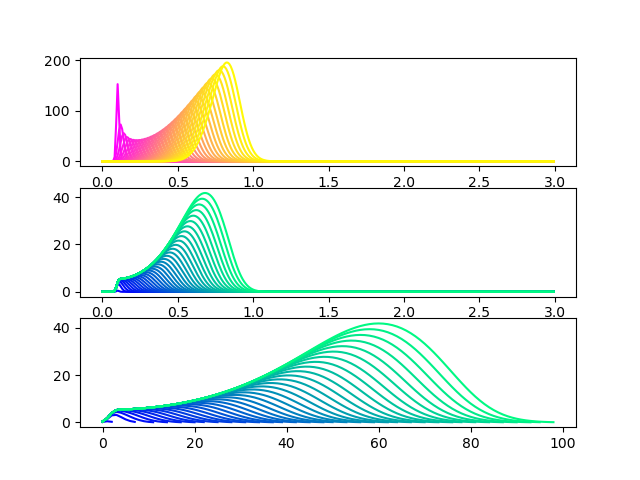

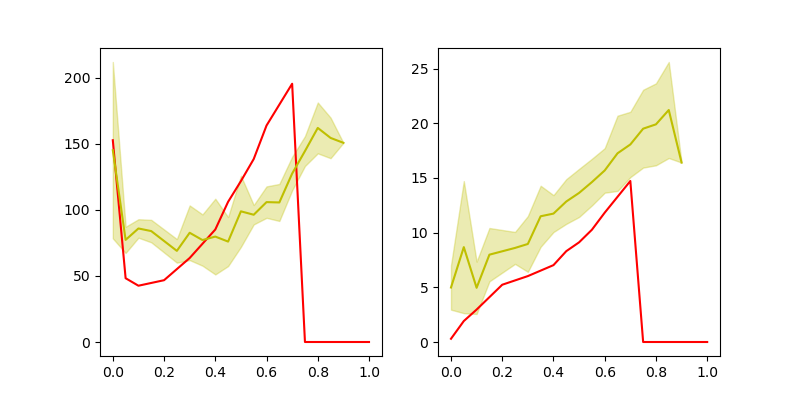

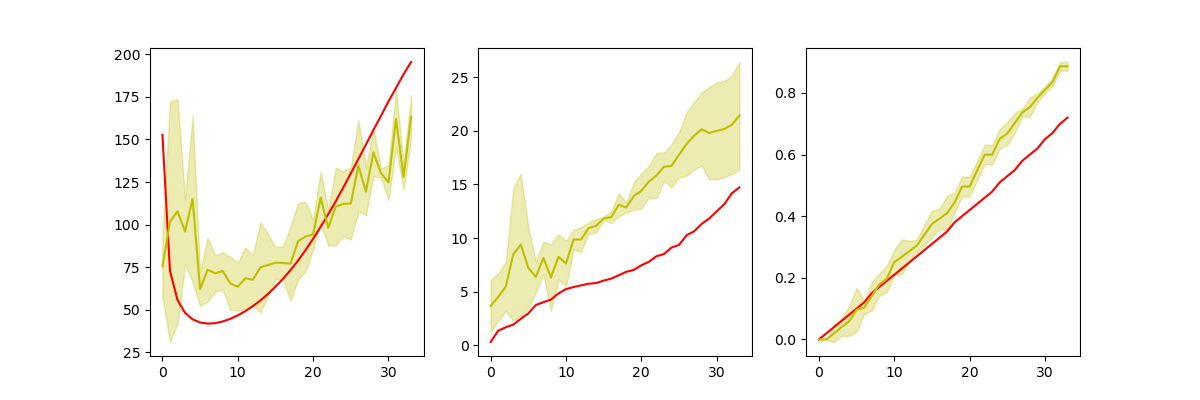

In [52]:
sim_name = 'AMALGAM/Python/bmx_fungi/output_fungi_11'
z_t = pd.read_csv(sim_name + '_data_t.csv')
z_r = pd.read_csv(sim_name + '_data_r.csv')
z_const = pd.read_csv(sim_name + '_data_const.csv')
        
z = [z_t, z_r, z_const['alpha'][0], z_const['beta'][0], z_const['vd'][0], z_const['sg'][0], z_const['D'][0], z_const['A'][0], z_const['s'][0], z_const['r0'][0], z_const['t0'][0]]
upar = [z[7], z[8], z[9]]
upar[2] = 0.1
        
par_best = [z[2], z[3], z[4], z[5], z[6]]# pd.read_csv(sim_name + '_pareto.csv', index_col=0)
PDE_best = PDE(par_best, upar, 34, 1)

# PDE_best = PDE([par_best.loc['median','alpha'], par_best.loc['median','beta'], par_best.loc['median','vd'], par_best.loc['median','sg'], par_best.loc['median','D']], upar, 34, 1)

figa, axa = plt.subplots(1,3, figsize = (12, 4))
axa[0].plot(PDE_best[0]['t'], PDE_best[0]['n'], color ='r')
axa[0].plot(z[0]['t'], z[0]['n'], color = 'y')
axa[0].fill_between(z[0]['t'], z[0]['n'] - z[0]['n_std'], z[0]['n'] + z[0]['n_std'], alpha = 0.3, color = 'y')
axa[1].plot(PDE_best[0]['t'], PDE_best[0]['rho'], color ='r')
axa[1].plot(z[0]['t'], z[0]['rho'], color = 'y')
axa[1].fill_between(z[0]['t'], z[0]['rho'] - z[0]['rho_std'], z[0]['rho'] + z[0]['rho_std'], alpha = 0.3, color = 'y')
axa[2].plot(PDE_best[0]['t'], PDE_best[0]['c'], color ='r')
axa[2].plot(z[0]['t'], z[0]['c'], color = 'y')
axa[2].fill_between(z[0]['t'], z[0]['c'] - z[0]['c_std'], z[0]['c'] + z[0]['c_std'], alpha = 0.3, color = 'y')
figb, axb = plt.subplots(1,2, figsize = (8, 4))
axb[0].plot(PDE_best[1]['r'],PDE_best[1]['n'], color ='r')
axb[0].plot(z[1]['r'], z[1]['n'], color ='y')
axb[0].fill_between(z[1]['r'], z[1]['n'] - z[1]['n_std'], z[1]['n'] + z[1]['n_std'], alpha = 0.3, color = 'y')
axb[1].plot(PDE_best[1]['r'], PDE_best[1]['rho'], color ='r')
axb[1].plot(z[1]['r'], z[1]['rho'], color = 'y')
axb[1].fill_between(z[1]['r'], z[1]['rho'] - z[1]['rho_std'], z[1]['rho'] + z[1]['rho_std'], alpha = 0.3, color = 'y')
plt.show()